In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

All libraries imported successfully!
Pandas version: 3.1.1
NumPy version: 2.5.5


# Exploratory Data Analysis (EDA)
## Predictive Maintenance Machine Learning Project

### 1. Introduction

The objective of this project is to analyse machine sensor readings and identify patterns that may indicate whether maintenance is required.

This exploratory data analysis aims to:
- Understand the structure and characteristics of the dataset.
- Identify missing values, duplicates and unusual readings.
- Investigate relationships between sensor measurements and maintenance requirements.
- Identify useful features for machine learning.
- Derive meaningful insights to support subsequent data preprocessing and model development.

In [2]:
# Load the machine readings dataset

df = pd.read_csv("data/proj_machine_readings.csv")

print("Dataset successfully loaded!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset successfully loaded!
Number of rows: 100000
Number of columns: 13


In [3]:
# Display the first 5 records

df.head()

,timestamp,machine_id,temperature,vibration,humidity,pressure,energy_consumption,machine_status,anomaly_flag,predicted_remaining_life,failure_type,downtime_risk,maintenance_required
0,2025-01-01 00:00:00,39,NaN,-28.65,79.96,3.73,2.16,1,0,106,Normal,0.0,0
1,2025-01-01 00:01:00,29,68.19,57.28,35.94,3.64,0.69,1,0,320,Normal,0.0,0
2,2025-01-01 00:02:00,15,98.94,50.20,72.06,1.00,2.49,1,1,19,Normal,1.0,1
3,2025-01-01 00:03:00,43,90.91,37.65,30.34,3.15,4.96,1,1,10,Normal,1.0,1
4,2025-01-01 00:04:00,8,72.32,40.69,56.71,2.68,0.63,2,0,65,Vibration Issue,0.0,1


In [4]:
# Display all column names

df.columns

Index(['timestamp', 'machine_id', 'temperature', 'vibration', 'humidity',
       'pressure', 'energy_consumption', 'machine_status', 'anomaly_flag',
       'predicted_remaining_life', 'failure_type', 'downtime_risk',
       'maintenance_required'],
      dtype='str')

## 2. Dataset Structure and Statistical Overview

This section examines the dataset's structure, data types and statistical characteristics.

The objective is to understand the nature of each variable, identify potential data quality issues and establish an initial understanding of the sensor readings.

In [5]:
# Display dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   timestamp                 100000 non-null  str    
 1   machine_id                100000 non-null  int64  
 2   temperature               86000 non-null   float64
 3   vibration                 100000 non-null  float64
 4   humidity                  100000 non-null  float64
 5   pressure                  100000 non-null  float64
 6   energy_consumption        100000 non-null  float64
 7   machine_status            100000 non-null  int64  
 8   anomaly_flag              100000 non-null  int64  
 9   predicted_remaining_life  100000 non-null  int64  
 10  failure_type              100000 non-null  str    
 11  downtime_risk             100000 non-null  float64
 12  maintenance_required      100000 non-null  int64  
dtypes: float64(6), int64(5), str(2)
memory usage: 9.9 MB


In [6]:
# Display statistical summaries for all columns

df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
timestamp,100000,100000,2025-01-01 00:00:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
machine_id,100000.0,NaN,NaN,NaN,25.49933,14.389439,1.0,13.0,25.0,38.0,50.0
temperature,86000.0,NaN,NaN,NaN,75.03441,10.036257,35.55,68.28,75.09,81.78,121.94
vibration,100000.0,NaN,NaN,NaN,43.324232,29.134306,-106.98,37.22,48.635,59.25,113.8
humidity,100000.0,NaN,NaN,NaN,54.995401,14.43796,30.0,42.52,54.98,67.5,80.0
pressure,100000.0,NaN,NaN,NaN,3.000405,1.152399,1.0,2.0,3.01,4.0,5.0
energy_consumption,100000.0,NaN,NaN,NaN,2.747064,1.297865,0.5,1.63,2.74,3.87,5.0
machine_status,100000.0,NaN,NaN,NaN,1.00205,0.446193,0.0,1.0,1.0,1.0,2.0
anomaly_flag,100000.0,NaN,NaN,NaN,0.08916,0.284976,0.0,0.0,0.0,0.0,1.0
predicted_remaining_life,100000.0,NaN,NaN,NaN,234.26916,150.063062,1.0,97.0,230.0,365.0,499.0


### 2.1 Initial Observations

The dataset contains 100,000 records and 13 columns, with a total memory usage of approximately 9.9 MB.

Several initial observations were identified:

- The temperature column contains 86,000 non-null values, indicating that 14% of its readings are missing.
- The timestamp column is currently stored as a string and may require conversion into a datetime format for time-based analysis.
- Machine ID is an identifier and should be treated as a categorical variable rather than a continuous numerical measurement.
- Machine status represents different machine operating states and should also be investigated as a categorical variable.
- Vibration readings contain negative values, with a minimum of -106.98 mm/s. These readings require further investigation.
- Failure type contains five unique categories, with Normal being the most frequently occurring category.
- The maintenance_required target has a positive class proportion of approximately 19.7%, indicating an imbalanced classification dataset.

These observations highlight the need for further data quality investigation, appropriate preprocessing and careful feature selection before developing machine learning models.

## 3. Data Quality Assessment

This section investigates missing values, duplicated records and unusual data entries to identify potential data quality issues that may affect subsequent analysis and model development.

### 3.1 Missing Value Analysis

In [7]:
# Calculate missing values and their percentages

missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage (%)": (df.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing Values",
    ascending=False
)

missing_summary

,Missing Values,Missing Percentage (%)
temperature,14000,14.0
timestamp,0,0.0
machine_id,0,0.0
vibration,0,0.0
humidity,0,0.0
pressure,0,0.0
energy_consumption,0,0.0
machine_status,0,0.0
anomaly_flag,0,0.0
predicted_remaining_life,0,0.0


In [8]:
# Check for duplicated records

duplicate_count = df.duplicated().sum()

print("Number of duplicated records:", duplicate_count)

Number of duplicated records: 0


In [9]:
# Count negative vibration readings

negative_vibration = (df["vibration"] < 0).sum()

print("Negative vibration readings:", negative_vibration)

Negative vibration readings: 6703


## 4. Categorical Variable Analysis

This section examines the distribution of categorical variables to understand machine operating conditions, failure categories and maintenance requirements.

In [10]:
# Examine the distribution of categorical variables

categorical_columns = [
    "machine_status",
    "anomaly_flag",
    "failure_type",
    "maintenance_required"
]

for column in categorical_columns:
    print(f"\nDistribution of {column}:")
    print(df[column].value_counts())
    print("\nPercentage:")
    print((df[column].value_counts(normalize=True) * 100).round(2))


Distribution of machine_status:
machine_status
1    80091
2    10057
0     9852
Name: count, dtype: int64

Percentage:
machine_status
1    80.09
2    10.06
0     9.85
Name: proportion, dtype: float64

Distribution of anomaly_flag:
anomaly_flag
0    91084
1     8916
Name: count, dtype: int64

Percentage:
anomaly_flag
0    91.08
1     8.92
Name: proportion, dtype: float64

Distribution of failure_type:
failure_type
Normal              91899
Vibration Issue      3129
Overheating          1989
Pressure Drop        1969
Electrical Fault     1014
Name: count, dtype: int64

Percentage:
failure_type
Normal              91.90
Vibration Issue      3.13
Overheating          1.99
Pressure Drop        1.97
Electrical Fault     1.01
Name: proportion, dtype: float64

Distribution of maintenance_required:
maintenance_required
0    80303
1    19697
Name: count, dtype: int64

Percentage:
maintenance_required
0    80.3
1    19.7
Name: proportion, dtype: float64


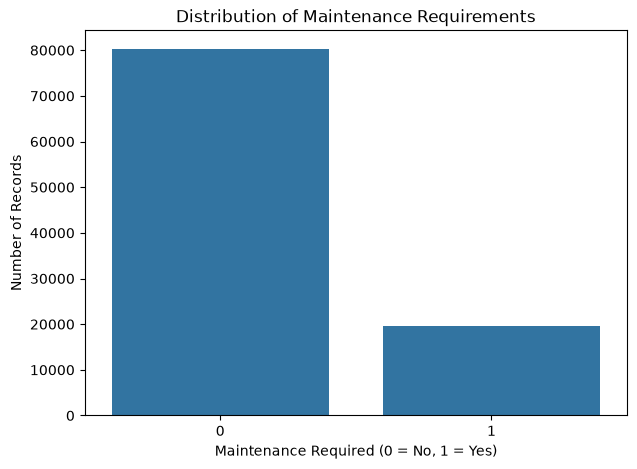

In [11]:
# Visualise maintenance requirements

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="maintenance_required")

plt.title("Distribution of Maintenance Requirements")
plt.xlabel("Maintenance Required (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")

plt.show()

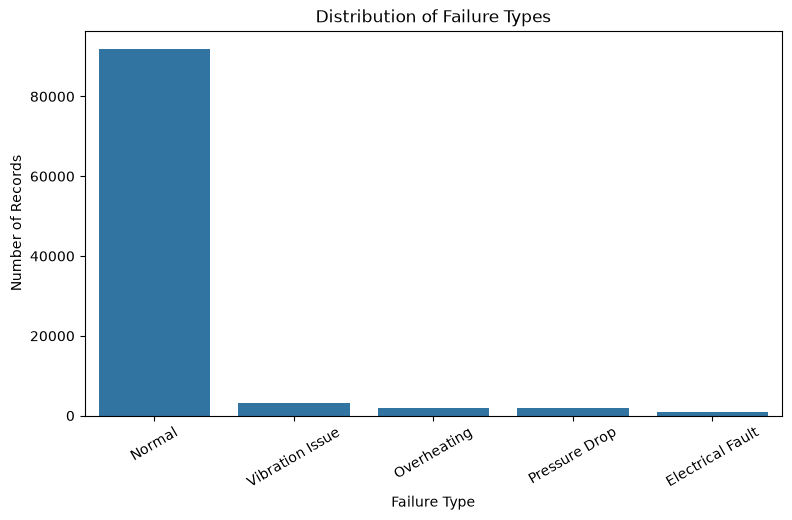

In [12]:
# Visualise failure types

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="failure_type",
    order=df["failure_type"].value_counts().index
)

plt.title("Distribution of Failure Types")
plt.xlabel("Failure Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)

plt.show()

## 5. Numerical Feature Distribution

This section visualises the distributions of numerical sensor readings to identify common operating ranges, unusual values and potential outliers.

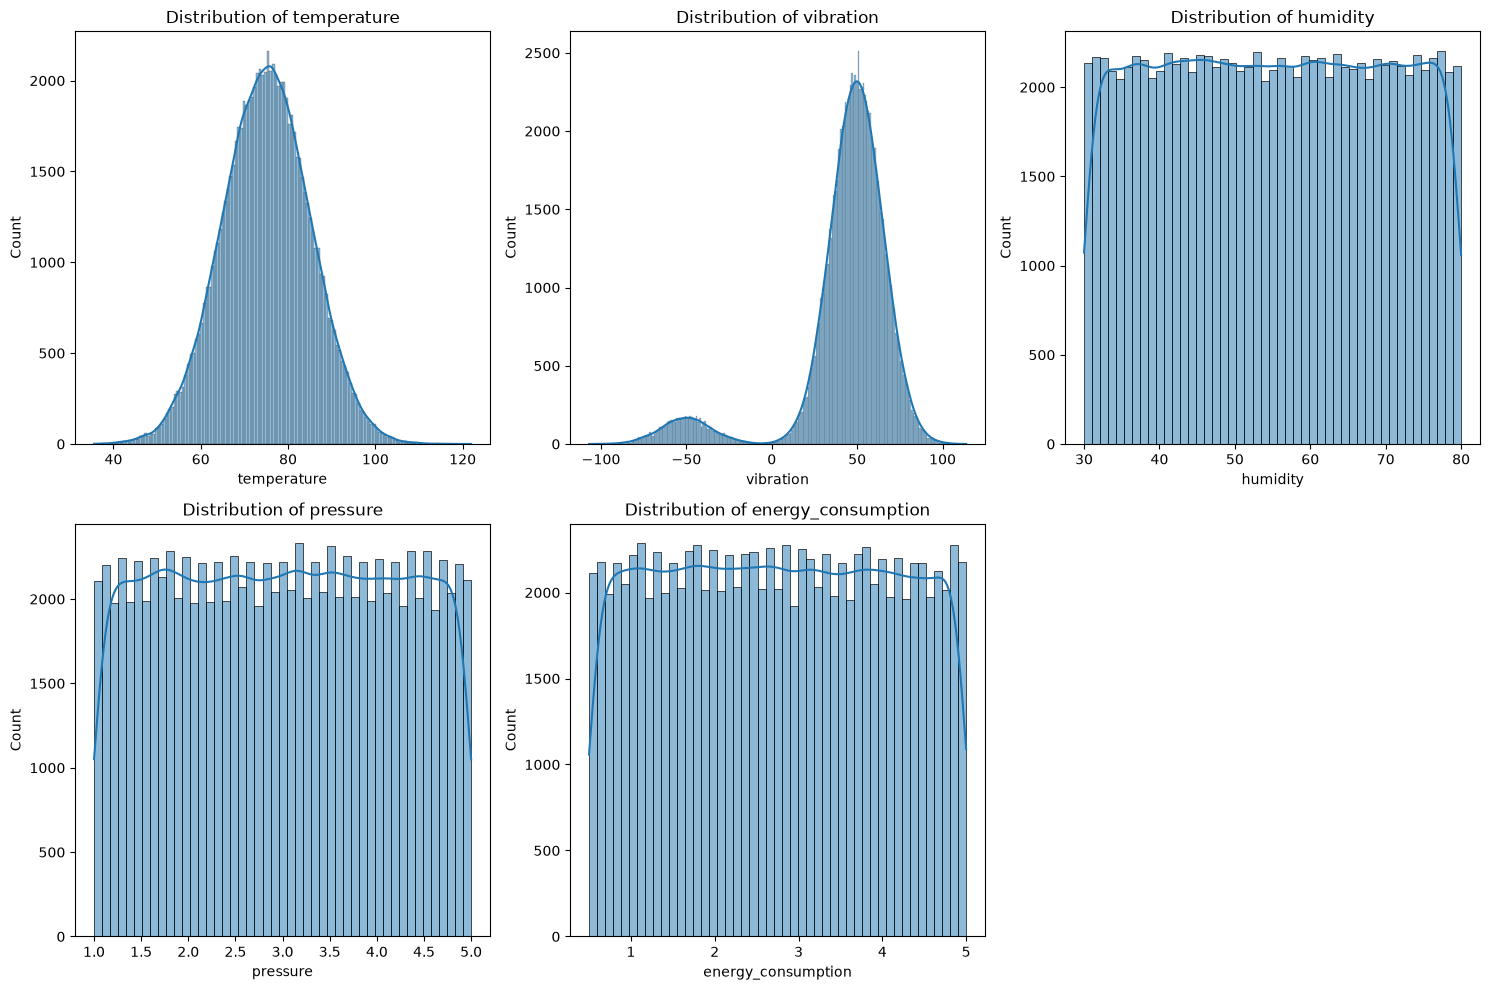

In [13]:
# Visualise numerical sensor distributions

numerical_columns = [
    "temperature",
    "vibration",
    "humidity",
    "pressure",
    "energy_consumption"
]

plt.figure(figsize=(15, 10))

for i, column in enumerate(numerical_columns, 1):
    plt.subplot(2, 3, i)
    sns.histplot(data=df, x=column, kde=True)
    plt.title(f"Distribution of {column}")

plt.tight_layout()
plt.show()

## 6. Correlation Analysis

This section examines the linear relationships between numerical sensor measurements and the maintenance requirement target.

A correlation matrix is used to identify potentially relevant relationships between variables.

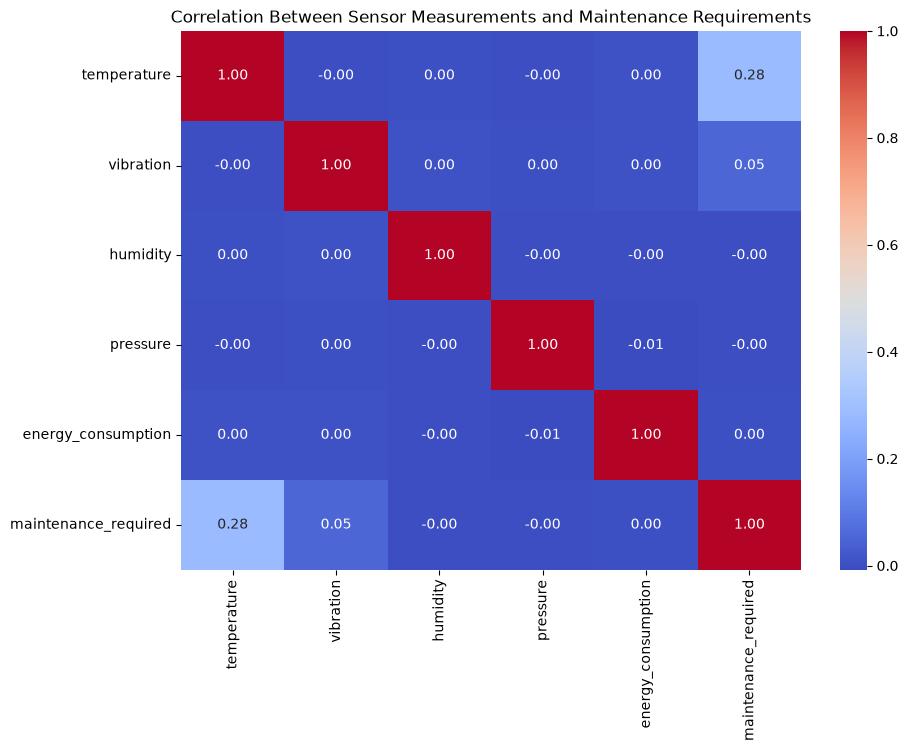

In [14]:
# Calculate correlations between sensor readings and target

correlation_columns = [
    "temperature",
    "vibration",
    "humidity",
    "pressure",
    "energy_consumption",
    "maintenance_required"
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Sensor Measurements and Maintenance Requirements")

plt.show()

### 6.1 Key Visualisation Findings

The visualisations revealed several important patterns:

**Categorical Variables**
- Approximately 80.09% of machines have a machine_status of 1.
- Approximately 8.92% of records are flagged as anomalies.
- Normal operating conditions account for approximately 91.9% of failure_type records.
- The target variable is imbalanced, with approximately 80.3% of records not requiring maintenance and 19.7% requiring maintenance.

**Numerical Variables**
- Temperature readings follow an approximately bell-shaped distribution, centred around 75°C.
- Vibration readings contain unusual negative values, including a secondary distribution below zero.
- Humidity, pressure and energy consumption show relatively uniform distributions across their respective ranges.

**Correlation Analysis**
- Temperature has the strongest positive linear correlation with maintenance_required (0.28).
- Vibration has a weak positive correlation (0.05).
- Humidity, pressure and energy consumption show almost no linear correlation with the target.

These findings suggest that temperature may be a useful predictor of maintenance requirements. However, further analysis is needed to understand relationships that may not be captured by linear correlation.

## 7. Sensor Measurements by Maintenance Requirement

This section compares sensor readings between machines that require maintenance and those that do not.

The objective is to identify differences in sensor measurements that may help distinguish between the two maintenance categories.

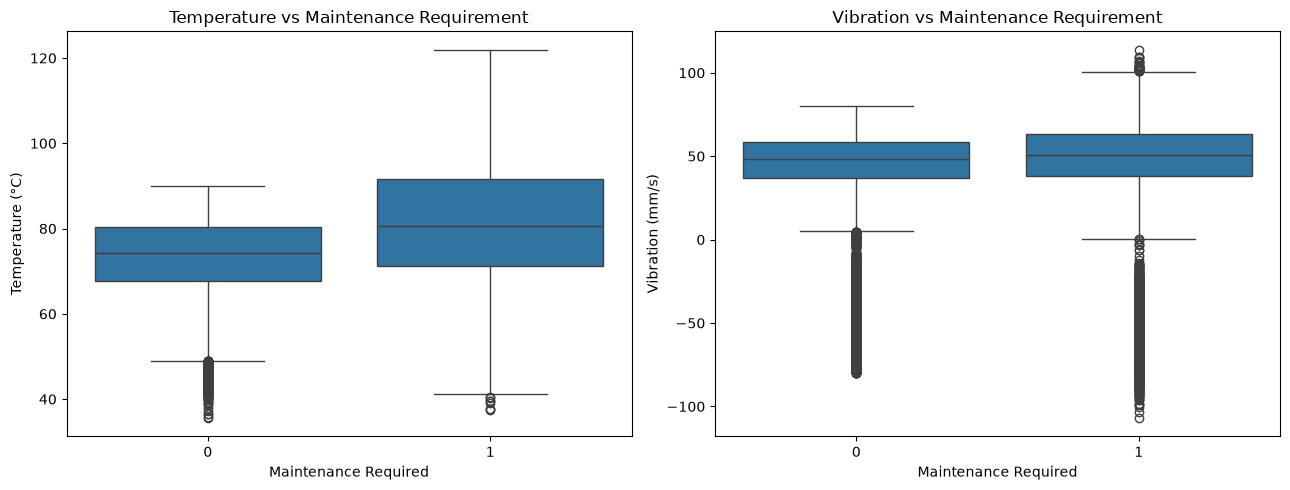

In [15]:
# Compare temperature and vibration against maintenance requirements

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=df,
    x="maintenance_required",
    y="temperature",
    ax=axes[0]
)

axes[0].set_title("Temperature vs Maintenance Requirement")
axes[0].set_xlabel("Maintenance Required")
axes[0].set_ylabel("Temperature (°C)")

sns.boxplot(
    data=df,
    x="maintenance_required",
    y="vibration",
    ax=axes[1]
)

axes[1].set_title("Vibration vs Maintenance Requirement")
axes[1].set_xlabel("Maintenance Required")
axes[1].set_ylabel("Vibration (mm/s)")

plt.tight_layout()
plt.show()

## 8. Potential Data Leakage Investigation

Some dataset variables may contain information that is closely related to the maintenance requirement target.

These variables are investigated to determine whether they could introduce data leakage during model training.

In [16]:
# Examine maintenance requirements across derived variables

derived_columns = [
    "machine_status",
    "anomaly_flag",
    "failure_type",
    "downtime_risk"
]

for column in derived_columns:
    print(f"\nMaintenance distribution by {column}:")

    display(
        pd.crosstab(
            df[column],
            df["maintenance_required"],
            normalize="index"
        ).mul(100).round(2)
    )


Maintenance distribution by machine_status:


maintenance_required,0,1
machine_status,,
0,89.08,10.92
1,89.31,10.69
2,0.00,100.00



Maintenance distribution by anomaly_flag:


maintenance_required,0,1
anomaly_flag,,
0,88.16,11.84
1,0.00,100.00



Maintenance distribution by failure_type:


maintenance_required,0,1
failure_type,,
Electrical Fault,0.00,100.00
Normal,87.38,12.62
Overheating,0.00,100.00
Pressure Drop,0.00,100.00
Vibration Issue,0.00,100.00



Maintenance distribution by downtime_risk:


maintenance_required,0,1
downtime_risk,,
0.00,88.16,11.84
0.88,0.00,100.00
0.92,0.00,100.00
0.93,0.00,100.00
0.94,0.00,100.00
0.97,0.00,100.00
0.98,0.00,100.00
0.99,0.00,100.00
1.00,0.00,100.00


## 9. EDA Conclusions

The exploratory data analysis identified several important findings:

1. The dataset contains 100,000 records and 13 columns, with 14% missing temperature values.

2. A total of 6,703 negative vibration readings were identified. These unusual readings require appropriate handling during preprocessing.

3. No duplicated records were found.

4. The target variable is imbalanced, with approximately 80.3% of records not requiring maintenance and 19.7% requiring maintenance.

5. Temperature showed the strongest positive linear correlation with maintenance requirements (0.28). Boxplot analysis also showed higher median temperatures among records requiring maintenance.

6. Several derived variables, including machine_status, anomaly_flag, failure_type and downtime_risk, showed extremely strong relationships with the target. These variables require careful consideration to prevent potential data leakage.

### Conclusion

The EDA findings provide a foundation for subsequent data cleaning, feature engineering and machine learning development. Appropriate missing-value imputation, handling of unusual sensor readings and careful feature selection will be important in preparing the dataset for predictive maintenance modelling.